# Raw column-profile distribution analysis

This notebook summarizes raw profiles before cleaning without storing trajectory arrays in a DataFrame. It processes one CSV at a time and does not modify profiles.

In [ ]:
from pathlib import Path
import re, gc
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_ROOT=Path('/mnt/newStor/paros/paros_WORK/xintong/results/column_analysis')
QC_ROOT=Path('/mnt/newStor/paros/paros_WORK/xintong/results/column_quality_qc')
QC_ROOT.mkdir(parents=True,exist_ok=True)
pattern=re.compile(r'^(D\d+)_(lh|rh)_(.+)_(md|fa|ad|rd)\.csv$')
DEPTHS=21
print('Reading:',RESULTS_ROOT)

Reading: /mnt/newStor/paros/paros_WORK/xintong/results/column_analysis


## 1. Online bad-point aggregation

Each file is loaded once, summarized, and released. Only compact counters are retained.

In [ ]:
from collections import defaultdict

# Reuse cached summaries when all expected files exist. Set RECOMPUTE=True only when new profiles arrive.
RECOMPUTE=False
expected=[QC_ROOT/'file_badpoint_summary.csv',QC_ROOT/'bad_points_per_column_summary.csv',QC_ROOT/'depth_bad_point_summary.csv',QC_ROOT/'bad_point_type_summary.csv']
if not RECOMPUTE and all(p.is_file() for p in expected):
    file_summary=pd.read_csv(QC_ROOT/'file_badpoint_summary.csv')
    category_summary=pd.read_csv(QC_ROOT/'bad_points_per_column_summary.csv')
    depth_summary=pd.read_csv(QC_ROOT/'depth_bad_point_summary.csv')
    type_summary=pd.read_csv(QC_ROOT/'bad_point_type_summary.csv')
    print('Loaded cached summaries; profile files were not reread.')
else:
    summary=[]; categories=defaultdict(int); depths=defaultdict(int); type_counts=defaultdict(int)
    for folder in sorted(RESULTS_ROOT.glob('D*/profiles_before_clean')):
      for path in sorted(folder.glob('*.csv')):
        m=pattern.match(path.name)
        if not m: continue
        subject,hemi,region,metric=m.groups()
        if path.stat().st_size==0:
          summary.append({'subject':subject,'hemisphere':hemi,'region':region,'metric':metric,'status':'empty','total_columns':0,'bad_points':0,'bad_columns':0,'one_bad_point':0,'two_bad_points':0,'three_or_more_bad_points':0,'consecutive_columns':0}); continue
        try: a=np.loadtxt(path,delimiter=',',ndmin=2)
        except Exception as e: summary.append({'subject':subject,'hemisphere':hemi,'region':region,'metric':metric,'status':'unreadable','total_columns':0,'bad_points':0,'bad_columns':0,'one_bad_point':0,'two_bad_points':0,'three_or_more_bad_points':0,'consecutive_columns':0,'error':str(e)}); continue
        if a.shape[1]!=DEPTHS: del a; continue
        finite=np.isfinite(a); bad=(~finite)|(a==0); counts=bad.sum(axis=1)
        for n in counts: categories[(subject,metric,'1' if n==1 else '2' if n==2 else '3_or_more' if n>=3 else '0')]+=1
        for d,n in enumerate(bad.sum(axis=0)):
          if n: depths[(metric,d)]+=int(n)
        type_counts[(metric,'exact_zero')]+=int((a==0).sum()); type_counts[(metric,'nan')]+=int(np.isnan(a).sum()); type_counts[(metric,'inf')]+=int(np.isinf(a).sum())
        consecutive=int(np.sum(np.any(bad[:,1:]&bad[:,:-1],axis=1))) if a.shape[1]>1 else 0
        summary.append({'subject':subject,'hemisphere':hemi,'region':region,'metric':metric,'status':'valid','total_columns':a.shape[0],'bad_points':int(bad.sum()),'bad_columns':int(np.any(bad,axis=1).sum()),'one_bad_point':int((counts==1).sum()),'two_bad_points':int((counts==2).sum()),'three_or_more_bad_points':int((counts>=3).sum()),'consecutive_columns':consecutive})
        del a,finite,bad,counts; gc.collect()
    file_summary=pd.DataFrame(summary); file_summary['bad_point_pct']=100*file_summary.bad_points/file_summary.total_columns.replace(0,np.nan)/DEPTHS
    file_summary.to_csv(QC_ROOT/'file_badpoint_summary.csv',index=False)
    category_summary=pd.DataFrame([{'subject':k[0],'metric':k[1],'category':k[2],'column_count':v} for k,v in categories.items()]); category_summary.to_csv(QC_ROOT/'bad_points_per_column_summary.csv',index=False)
    depth_summary=pd.DataFrame([{'metric':k[0],'depth':k[1],'bad_point_count':v} for k,v in depths.items()]); depth_summary.to_csv(QC_ROOT/'depth_bad_point_summary.csv',index=False)
    type_summary=pd.DataFrame([{'metric':k[0],'type':k[1],'count':v} for k,v in type_counts.items()]); type_summary.to_csv(QC_ROOT/'bad_point_type_summary.csv',index=False)
display(file_summary.head()); display(type_summary)

Loaded cached summaries; profile files were not reread.


,subject,hemisphere,region,metric,status,total_columns,bad_points,bad_columns,one_bad_point,two_bad_points,three_or_more_bad_points,consecutive_columns,bad_point_pct
0,D0007,lh,bankssts,ad,valid,1201,0,0,0,0,0,0,0.0
1,D0007,lh,bankssts,fa,valid,1201,0,0,0,0,0,0,0.0
2,D0007,lh,bankssts,md,valid,1201,0,0,0,0,0,0,0.0
3,D0007,lh,bankssts,rd,valid,1201,0,0,0,0,0,0,0.0
4,D0007,lh,caudalanteriorcingulate,ad,valid,800,0,0,0,0,0,0,0.0


,metric,type,count
0,ad,exact_zero,1378443
1,ad,NaN,2122693
2,ad,inf,0
3,fa,exact_zero,1382711
4,fa,NaN,2133702
5,fa,inf,0
6,md,exact_zero,1383288
7,md,NaN,2136560
8,md,inf,0
9,rd,exact_zero,1378382


## 2. Subject and population summaries

These are the compact tables used for population-level QC.

In [ ]:
subject_summary=file_summary.groupby('subject',as_index=False).agg(total_columns=('total_columns','sum'),bad_points=('bad_points','sum'),bad_columns=('bad_columns','sum'),one_bad_point=('one_bad_point','sum'),two_bad_points=('two_bad_points','sum'),three_or_more_bad_points=('three_or_more_bad_points','sum'),empty_files=('status',lambda s:int((s=='empty').sum())))
subject_summary['bad_point_pct']=100*subject_summary.bad_points/(subject_summary.total_columns*DEPTHS).replace(0,np.nan)
subject_summary.to_csv(QC_ROOT/'subject_badpoint_summary.csv',index=False)
region_summary=file_summary.groupby(['subject','hemisphere','region','metric'],as_index=False).agg(total_columns=('total_columns','sum'),bad_points=('bad_points','sum'),bad_columns=('bad_columns','sum'),one_bad_point=('one_bad_point','sum'),two_bad_points=('two_bad_points','sum'),three_or_more_bad_points=('three_or_more_bad_points','sum'),consecutive_columns=('consecutive_columns','sum'))
region_summary.to_csv(QC_ROOT/'subject_hemisphere_region_metric_summary.csv',index=False)
display(subject_summary); display(region_summary.head())

,subject,total_columns,bad_points,bad_columns,one_bad_point,two_bad_points,three_or_more_bad_points,empty_files,bad_point_pct
0,D0007,888508,9240,1076,48,108,920,0,0.049521
1,D0029,966196,144112,11864,448,376,11040,0,0.710257
2,D0049,995036,15068,2148,272,240,1636,0,0.072110
3,D0050,1036888,3236,708,152,120,436,0,0.014861
4,D0051,837108,4772,720,112,72,536,0,0.027146
...,...,...,...,...,...,...,...,...,...
184,D0280,1104276,5380,1000,120,128,752,0,0.023200
185,D0281,980748,165360,12488,596,560,11332,0,0.802886
186,D0282,978300,940,220,36,36,148,0,0.004575
187,D0283,1049868,48748,5472,552,524,4396,0,0.221107


,subject,hemisphere,region,metric,total_columns,bad_points,bad_columns,one_bad_point,two_bad_points,three_or_more_bad_points,consecutive_columns
0,D0007,lh,bankssts,ad,1201,0,0,0,0,0,0
1,D0007,lh,bankssts,fa,1201,0,0,0,0,0,0
2,D0007,lh,bankssts,md,1201,0,0,0,0,0,0
3,D0007,lh,bankssts,rd,1201,0,0,0,0,0,0
4,D0007,lh,caudalanteriorcingulate,ad,800,0,0,0,0,0,0


## 3. Population visualizations

The next code cell displays the cached summary results once.

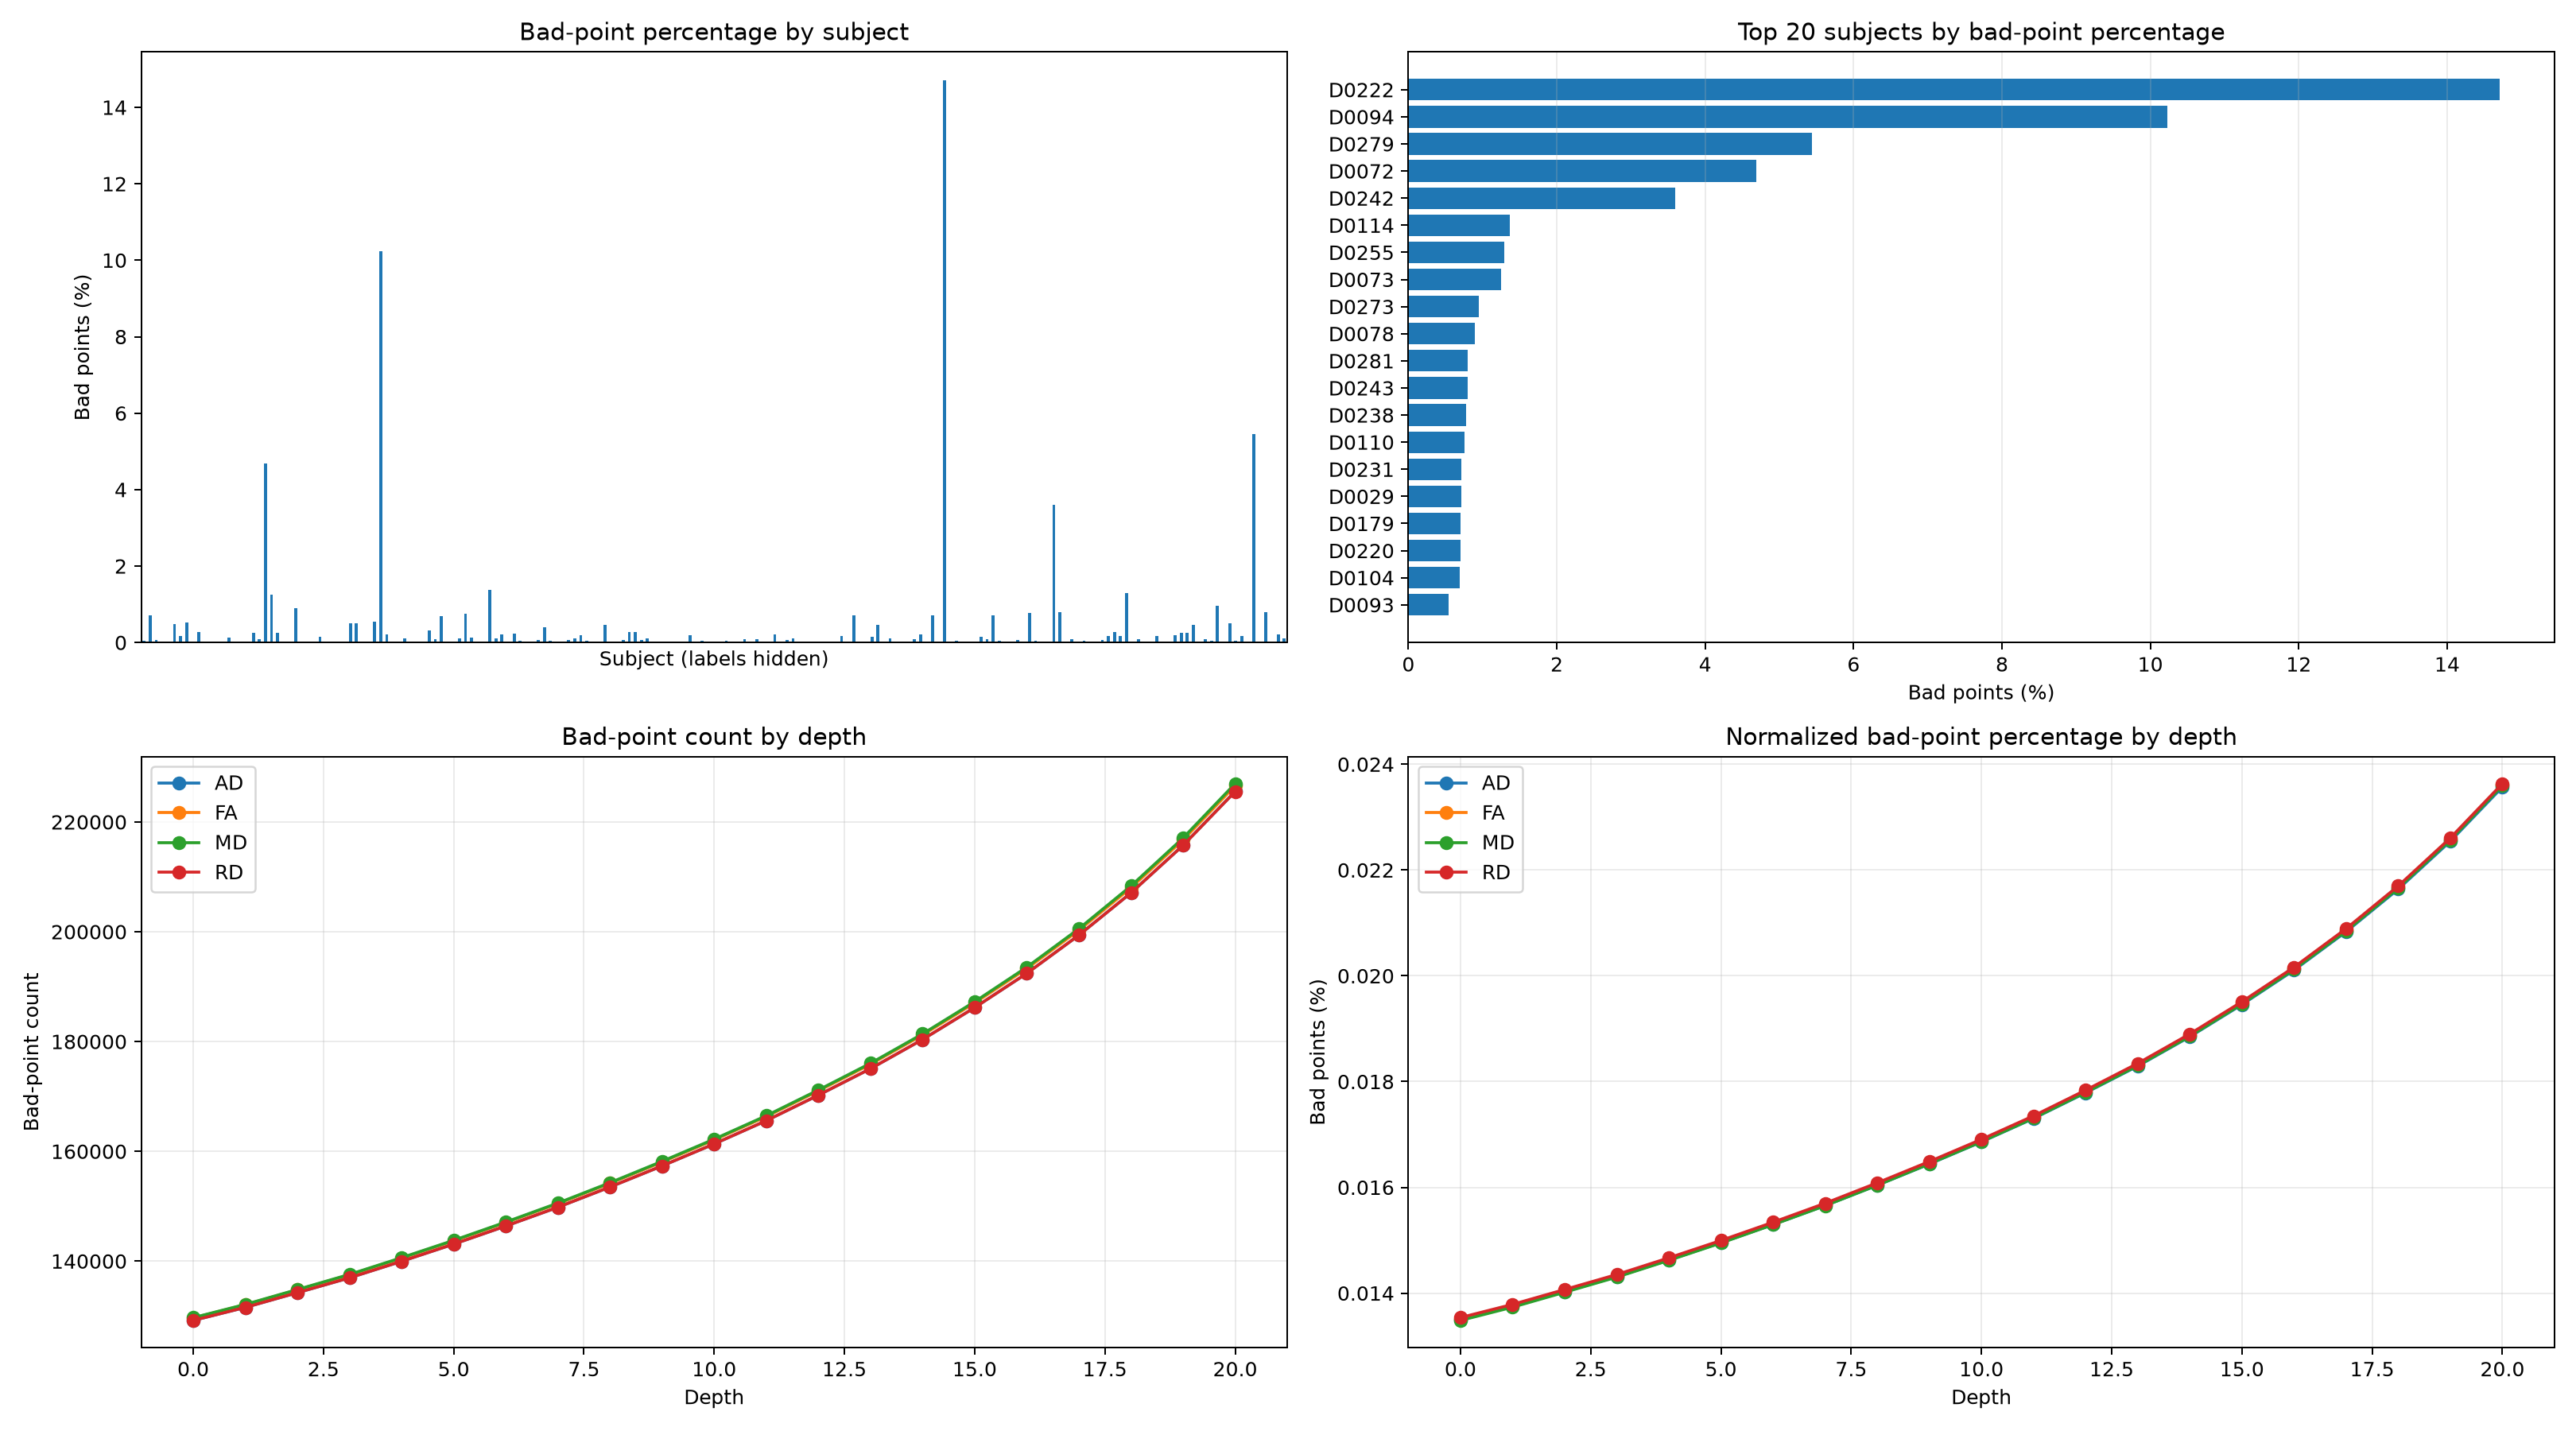

In [ ]:
from IPython.display import Image, display
import matplotlib.pyplot as plt
plt.close('all')

subject_summary = pd.read_csv(QC_ROOT / 'subject_badpoint_summary.csv')
depth_summary = pd.read_csv(QC_ROOT / 'depth_bad_point_summary.csv')

fig, axes = plt.subplots(2, 2, figsize=(18, 10))
axes = axes.ravel()

# 1. All subjects
all_subjects = subject_summary.sort_values('subject')
all_subjects.plot(x='subject', y='bad_point_pct', kind='bar', ax=axes[0], legend=False)
axes[0].set_title('Bad-point percentage by subject')
axes[0].set_ylabel('Bad points (%)')
axes[0].set_xlabel('Subject (labels hidden)')
axes[0].set_xticks([])

# 2. Top 20 subjects
top = subject_summary.nlargest(20, 'bad_point_pct').sort_values('bad_point_pct')
axes[1].barh(top['subject'], top['bad_point_pct'])
axes[1].set_title('Top 20 subjects by bad-point percentage')
axes[1].set_xlabel('Bad points (%)')
axes[1].grid(axis='x', alpha=0.25)

# 3. Absolute count by depth
for metric, group in depth_summary.groupby('metric'):
    group = group.sort_values('depth')
    axes[2].plot(group['depth'], group['bad_point_count'], marker='o', label=metric.upper())
axes[2].set_title('Bad-point count by depth')
axes[2].set_xlabel('Depth')
axes[2].set_ylabel('Bad-point count')
axes[2].legend()
axes[2].grid(alpha=0.25)

# 4. Normalized percentage by depth
file_summary = pd.read_csv(QC_ROOT / 'file_badpoint_summary.csv')
total_by_metric = file_summary.groupby('metric')['total_columns'].sum() * DEPTHS
for metric, group in depth_summary.groupby('metric'):
    group = group.sort_values('depth').copy()
    group['bad_point_pct'] = 100 * group['bad_point_count'] / total_by_metric.get(metric, np.nan)
    axes[3].plot(group['depth'], group['bad_point_pct'], marker='o', label=metric.upper())
axes[3].set_title('Normalized bad-point percentage by depth')
axes[3].set_xlabel('Depth')
axes[3].set_ylabel('Bad points (%)')
axes[3].legend()
axes[3].grid(alpha=0.25)

fig.tight_layout()
out = QC_ROOT / 'population_badpoint_overview.png'
fig.savefig(out, dpi=180)
plt.close(fig)
display(Image(filename=str(out)))
